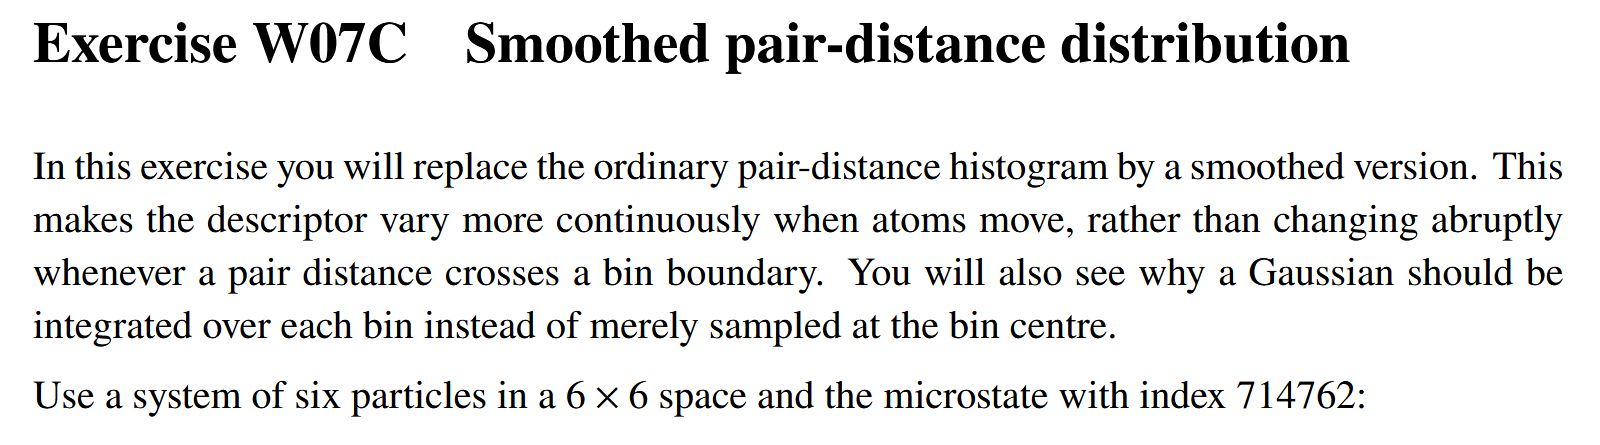

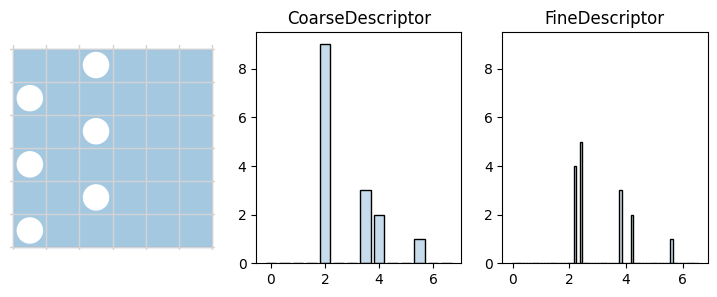

In [1]:
import numpy as np
import matplotlib.pyplot as plt 
from week07 import *
from Pairdistance import *

MicroState = make_microstate_factory(N=6, L=6)
i = 714762
m = MicroState(i)

class CoarseDescriptor(DescriptorBase):
    centers = np.arange(0.0, 6.6, 0.5)
    ylim = [0.0, 9.5]

    def __call__(self, pos):
        dist_vector = pdist(pos)
        hist = np.histogram(dist_vector, bins=self.edges)[0]
        return hist.tolist()

class FineDescriptor(DescriptorBase):
    centers = np.arange(0.0, 6.6, 0.1)
    ylim = [0.0, 9.5]

    def __call__(self, pos):
        dist_vector = pdist(pos)
        hist = np.histogram(dist_vector, bins=self.edges)[0]
        return hist.tolist()

fig, ax = plt.subplots(1, 3, figsize=(9, 3))

m.plot(ax[0])

m = MicroState(i, CoarseDescriptor())
m.plot_descriptor(ax[1])

m = MicroState(i, FineDescriptor())
m.plot_descriptor(ax[2])

## What is lost and gained by more bins?

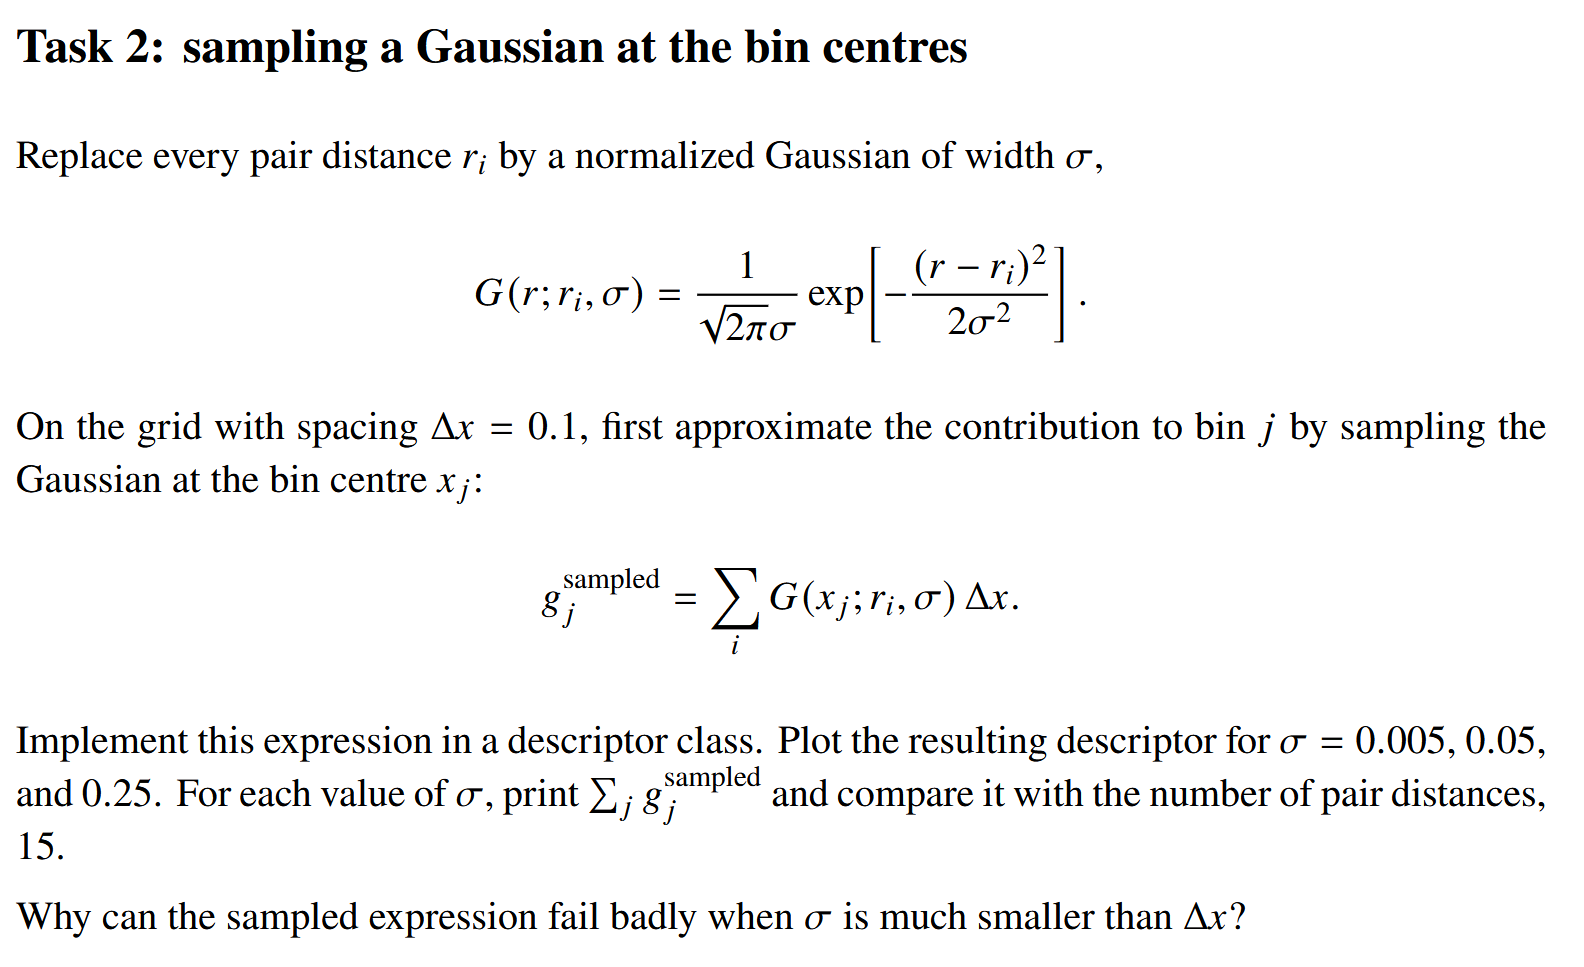

Sigma 0.005: Sampled sum = 60.895
Sigma 0.05: Sampled sum = 15.089
Sigma 0.25: Sampled sum = 15.000


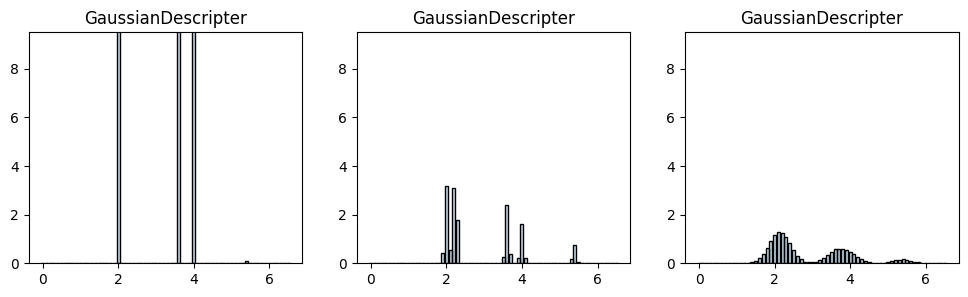

In [ ]:
class GaussianDescripter(DescriptorBase):
    def __init__(self, *args, sigma=0.5, dx=0.1, **kwargs):
        super().__init__(*args, **kwargs)
        self.sigma = sigma 
        self.dx = dx

    centers = np.arange(0.0, 6.6, 0.1)
    ylim = [0.0, 9.5]

    def gaussian(self, r, rj):
        return 1/np.sqrt(2*np.pi) / self.sigma*np.exp(-(r-rj)**2 / (2*self.sigma**2))

    def __call__(self, pos):
        dist_vector = pdist(pos)
        desc = []
        for xj in self.centers:
            gj = sum(self.gaussian(xj, dist_vector))*self.dx
            desc.append(gj)
        
        return desc

# Evaluate and print sums
sigmas = [0.005, 0.05, 0.25]

fig, ax = plt.subplots(1, 3, figsize=(12,3))

for i, sig in enumerate(sigmas):
    desc_sampled = GaussianDescripter(sigma=sig)
    m_samp = MicroState(714762, descriptor_method=desc_sampled)
    print(f"Sigma {sig}: Sampled sum = {np.sum(m_samp.descriptor):.3f}")
    m_samp.plot_descriptor(ax[i])

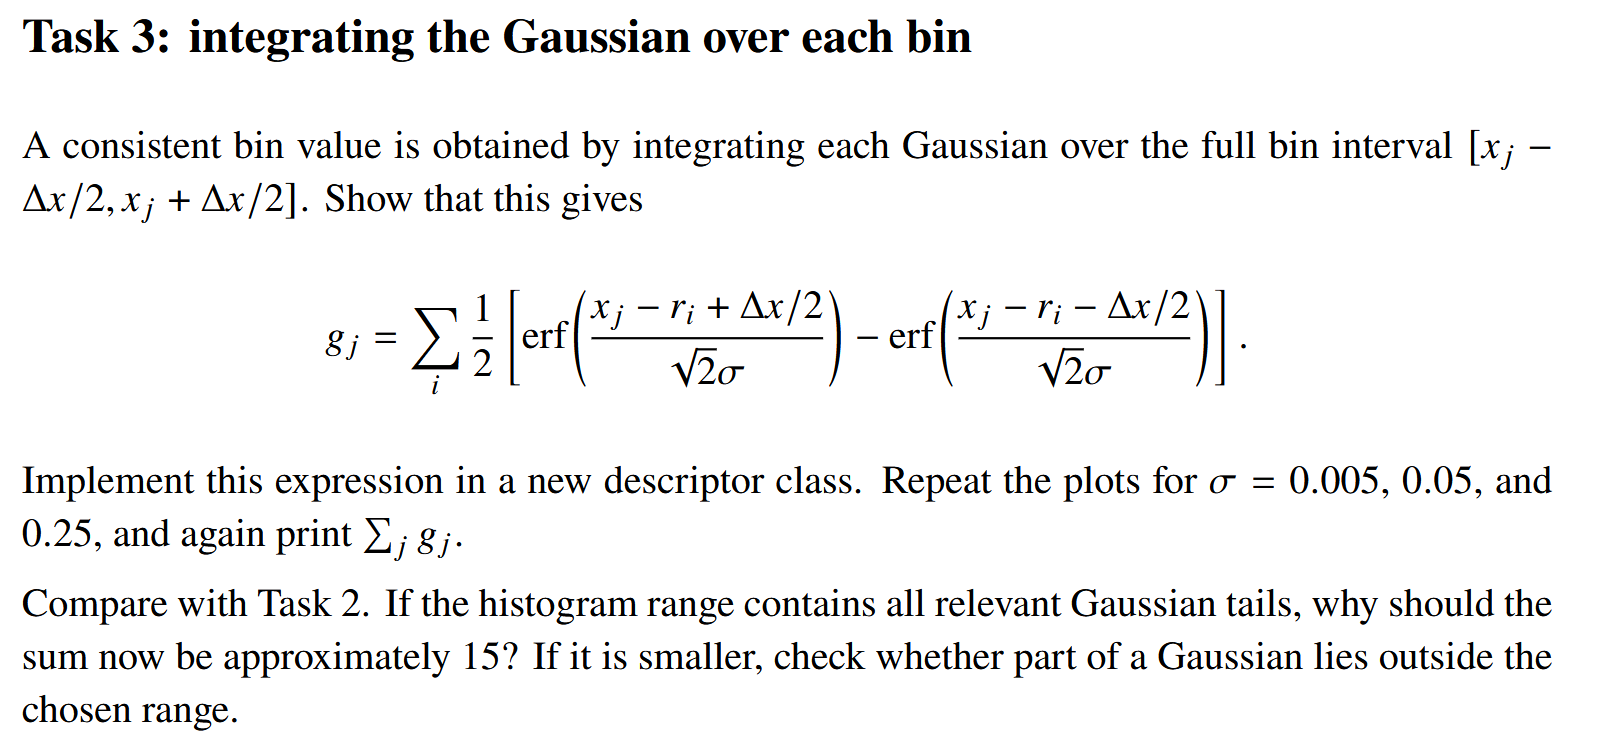

Sigma 0.005: Sampled sum = 15.000
Sigma 0.05: Sampled sum = 15.000
Sigma 0.25: Sampled sum = 15.000


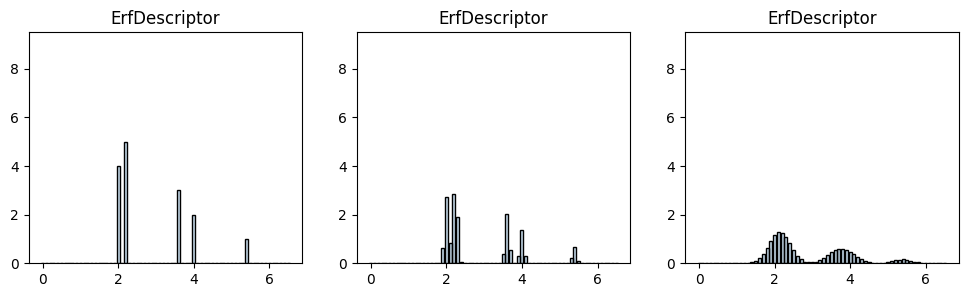

In [7]:
from scipy.special import erf

class ErfDescriptor(DescriptorBase):
    def __init__(self, *args, sigma=0.5, dx=0.1, **kwargs):
        super().__init__(*args, **kwargs)
        self.sigma = sigma 
        self.dx = dx

    centers = np.arange(0.0, 6.6, 0.1)
    ylim = [0.0, 9.5]

    def __call__(self, pos):
        dist_vector = pdist(pos)
        desc = []
        for xj in self.centers:
            gj = sum(0.5 * (erf((xj - dist_vector + self.dx/2) / np.sqrt(2)/self.sigma) 
                          - erf((xj - dist_vector - self.dx/2) / np.sqrt(2)/self.sigma)))
            desc.append(gj)
        
        return desc

# Evaluate and print sums
sigmas = [0.005, 0.05, 0.25]

fig, ax = plt.subplots(1, 3, figsize=(12,3))

for i, sig in enumerate(sigmas):
    desc_sampled = ErfDescriptor(sigma=sig)
    m_samp = MicroState(714762, descriptor_method=desc_sampled)
    print(f"Sigma {sig}: Sampled sum = {np.sum(m_samp.descriptor):.3f}")
    m_samp.plot_descriptor(ax[i])

## Explain why the first now gives 15 and not 60

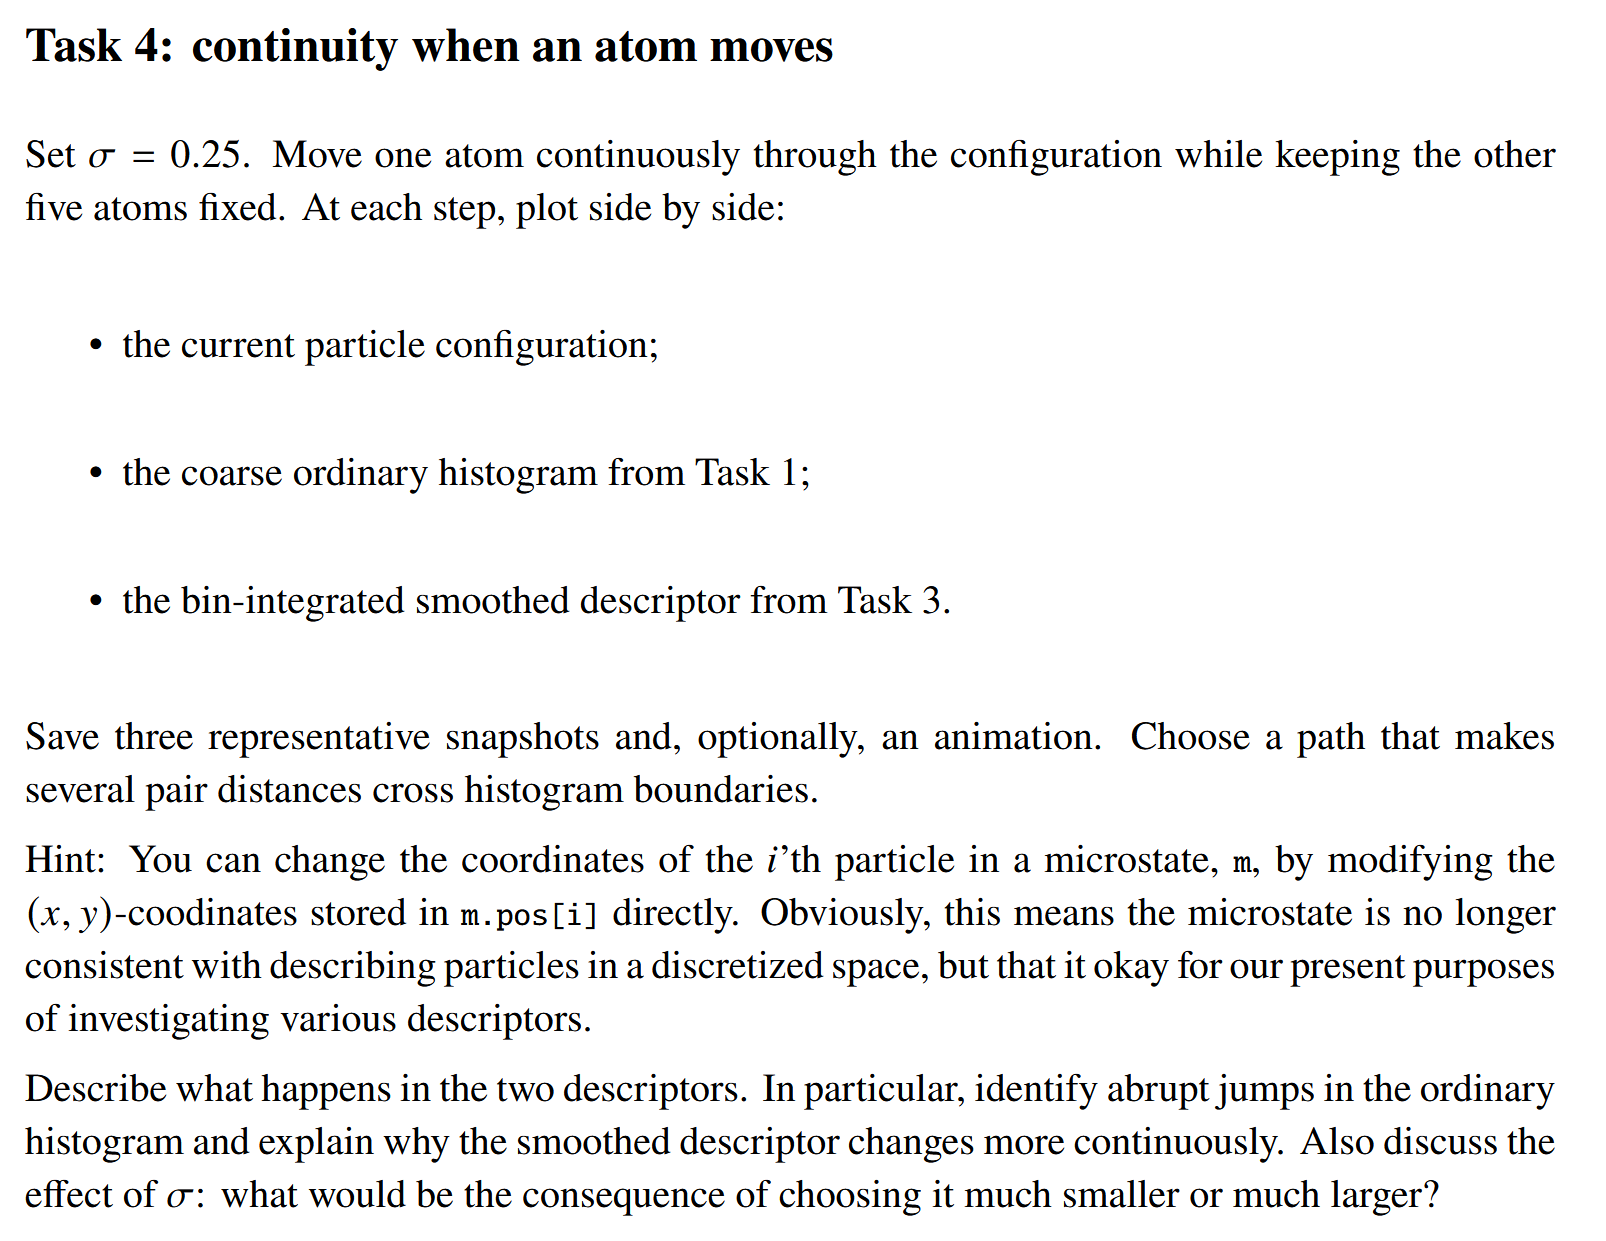

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Setup System and Path
MicroState = make_microstate_factory(N=6, L=6)
m = MicroState(714762)

desc_coarse = CoarseDescriptor()
desc_conv = ErfDescriptor(sigma=0.25)

# Define a continuous path for atom 0 to move across the grid
frames = 60
start_pos = m.pos[0].copy()
path_x = np.linspace(start_pos[0], start_pos[0] - 2, frames)
path_y = np.linspace(start_pos[1], start_pos[1] - 4, frames)

# Generate Interactive Animation
fig_anim, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4))

# Set static titles for the histograms once so they don't reset
ax2.set_title("Coarse Ordinary Hist")
ax3.set_title("Convoluted (Smoothed) Hist")

def update(frame_idx):
    # Update position of the first atom continuously 
    m.pos[0] = [path_x[frame_idx], path_y[frame_idx]]
    
    ax1.clear()
    m.plot(ax1, label='Index')
    ax1.set_title("Configuration")
    
    m.descriptor_method = desc_coarse
    m.plot_descriptor(ax2, add_title=False)
    
    m.descriptor_method = desc_conv
    m.plot_descriptor(ax3, add_title=False)

ani = FuncAnimation(fig_anim, update, frames=frames, interval=100)
plt.close(fig_anim) # Prevent duplicate static plot

# Display interactive video player in the notebook
HTML(ani.to_jshtml())